# Circuit clusters — T5 degradation transfer

Circuits the 2026 season has not visited yet borrow tyre coefficients from circuits
it has. The clustering runs on era-2024 behaviour every circuit has data for:
degradation amplitude (abrasiveness), full-throttle fraction and braking energy
(layout), and pit-lane loss (a stable circuit fingerprint). k is chosen by
silhouette over the configured range, seeded so a rerun of `make fit` cannot
reshuffle transfer donors. A transferred coefficient carries `low_confidence: true`
and its donors, forever.

In [1]:
import numpy as np
import pandas as pd

from senna import config
from senna.data.db import database_url, engine_for
from senna.physics.fits import frames, plots
from senna.physics.fits.gate import assert_quality_reports

fits_cfg = config.load("fits")
ingest_cfg = config.load("ingest")
CALIB = config.get(config.load("data_split"), "calibration_rounds")
SLICKS = ("SOFT", "MEDIUM", "HARD")

assert_quality_reports(
    config.get(ingest_cfg, "seasons"),
    config.REPO_ROOT / config.get(ingest_cfg, "quality.report_dir"),
)
engine = engine_for(database_url())
conn = await engine.connect()
index = await frames.circuit_index(conn, CALIB)
index[["slug", "era"]].drop_duplicates().groupby("era").size()

era
2024    25
2026     6
dtype: int64

In [2]:
import yaml

params = yaml.safe_load(open(config.REPO_ROOT / "configs" / "physics_params.yaml"))
feature_rows = {}
for slug, circuit in params["circuits"].items():
    deg_2024 = (circuit.get("degradation") or {}).get(2024) or {}
    energy_2024 = (circuit.get("energy") or {}).get(2024) or {}
    pit = circuit.get("pit_loss") or {}
    if not (deg_2024 and energy_2024 and pit):
        continue
    feature_rows[slug] = {
        "deg_a_2024": float(np.mean([row["a"] for row in deg_2024.values()])),
        "full_throttle_frac": energy_2024["full_throttle_frac"],
        "braking_energy_mj_per_lap": energy_2024["braking_energy_mj_per_lap"],
        "pit_loss_s": pit["mean_s"],
    }
features = pd.DataFrame.from_dict(feature_rows, orient="index")
features

,deg_a_2024,full_throttle_frac,braking_energy_mj_per_lap,pit_loss_s
abu_dhabi_grand_prix,0.000469,0.5212,11.0475,22.834
australian_grand_prix,0.000022,0.6168,8.9175,18.680
austrian_grand_prix,0.000209,0.5700,9.5080,22.159
azerbaijan_grand_prix,0.000321,0.5299,14.8380,20.784
bahrain_grand_prix,0.000710,0.4791,13.1607,25.359
belgian_grand_prix,0.002438,0.5982,11.2084,23.507
british_grand_prix,0.000375,0.5765,8.1486,29.654
chinese_grand_prix,0.001339,0.4496,11.3091,24.112
dutch_grand_prix,0.000367,0.4757,8.4709,22.038
emilia_romagna_grand_prix,0.000689,0.5805,10.9707,30.994


/Users/saad/senna/docs/fits/clusters/silhouette_curve.png


,cluster,stored
abu_dhabi_grand_prix,0,0
singapore_grand_prix,0,0
saudi_arabian_grand_prix,0,0
qatar_grand_prix,0,0
miami_grand_prix,0,0
mexico_city_grand_prix,0,0
japanese_grand_prix,0,0
são_paulo_grand_prix,0,0
hungarian_grand_prix,0,0
italian_grand_prix,0,0


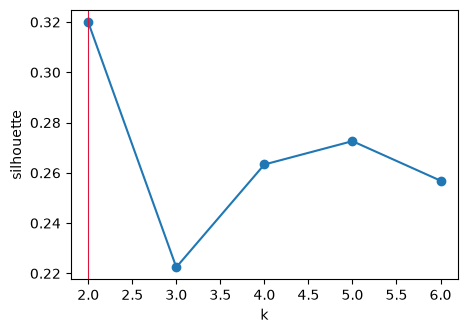

In [3]:
import matplotlib.pyplot as plt

from senna.physics.fits.clusters import assign_clusters

clustering = assign_clusters(
    features,
    k_range=tuple(config.get(fits_cfg, "clusters.k_range")),
    seed=config.get(fits_cfg, "clusters.seed"),
)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(list(clustering.silhouettes), list(clustering.silhouettes.values()), marker="o")
ax.axvline(clustering.k, color="crimson", linewidth=0.8)
ax.set_xlabel("k")
ax.set_ylabel("silhouette")
print(plots.save_figure(fig, "clusters", "silhouette_curve"))

assignments = pd.Series(clustering.assignments, name="cluster").sort_values()
stored = pd.Series(
    {s: v for s, v in params["clusters"]["assignments"].items()}, name="stored"
)
pd.concat([assignments, stored], axis=1)

The stored column confirms the yaml carries exactly this clustering.

In [4]:
transfer_rows = []
for slug, circuit in params["circuits"].items():
    for compound, row in ((circuit.get("degradation") or {}).get(2026) or {}).items():
        if isinstance(row, dict) and row.get("source_circuit"):
            transfer_rows.append(
                {
                    "circuit": slug,
                    "compound": compound,
                    "a": row["a"],
                    "b": row["b"],
                    "donors": row["source_circuit"],
                }
            )
pd.DataFrame(transfer_rows)

,circuit,compound,a,b,donors
0,abu_dhabi_grand_prix,HARD,0.000428,1.6530,"australian_grand_prix,chinese_grand_prix,japan..."
1,abu_dhabi_grand_prix,MEDIUM,0.000354,1.0851,"australian_grand_prix,chinese_grand_prix,japan..."
2,abu_dhabi_grand_prix,SOFT,0.000000,0.3000,"australian_grand_prix,chinese_grand_prix,miami..."
3,austrian_grand_prix,HARD,0.000187,1.6530,"australian_grand_prix,chinese_grand_prix,japan..."
4,austrian_grand_prix,MEDIUM,0.000187,1.0851,"australian_grand_prix,chinese_grand_prix,japan..."
5,austrian_grand_prix,SOFT,0.000000,0.3000,"australian_grand_prix,chinese_grand_prix,miami..."
6,azerbaijan_grand_prix,HARD,0.000176,1.6530,"australian_grand_prix,chinese_grand_prix,japan..."
7,azerbaijan_grand_prix,MEDIUM,0.000218,1.0851,"australian_grand_prix,chinese_grand_prix,japan..."
8,bahrain_grand_prix,HARD,0.000414,1.6530,"australian_grand_prix,chinese_grand_prix,japan..."
9,bahrain_grand_prix,MEDIUM,0.000612,1.0851,"australian_grand_prix,chinese_grand_prix,japan..."


In [5]:
await conn.close()
await engine.dispose()